# Motifs, states and baselines: visual exploration

Mouse 720762, deep prelimbic LFP (PL5), the report's 10 bands. Algorithm in `src/epoch_motifs.py`:

1. Detect motifs (relaxed Mishler) separately in each of the 7 epochs; merge into one library when sign templates
   match (|cos| ≥ 0.9).
2. **Expression** of every motif at every second, in that second's own epoch units, (x − μ_e)/σ_e.
3. Per motif and epoch, **1, 2 or 3 Gaussians** on the expression: k is accepted only if its held-out gain beats all
   10 phase-randomised surrogates. Responsibilities where k ≥ 2; number of peaks to tell real poles from a skewed hump.
4. **Zero** label (all bands near the own-epoch baseline, RMS < 0.5) and a **suppression** label (isoflurane seconds
   with every band low; heuristic).
5. **State** described separately: each epoch's baseline shift from the global baseline, split into along each motif,
   inside all motifs, and perpendicular.

Two hypotheses are tested visually:

- **H1, across states:** if a motif direction persists across states, its baseline (where the cloud of seconds sits
  along it) should visibly move when the state changes.
- **H2, within an epoch:** the direction stays the same but the baseline drifts along the axis, so the poles move over
  time. If so, a sliding baseline should replace the epoch mean, and some "extra Gaussians" may just be drift.

Interactive 3-D figures are also saved as HTML in the output folder.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio

sys.path.insert(0, "..")
from src import epoch_motifs as em
from src import session_data as sd
from src.state_motifs import band_labels
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+notebook"

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
OUT = REPO / "data" / "out" / "2026-11-10_states_and_baselines"
OUT.mkdir(parents=True, exist_ok=True)
names = band_labels()
EP = list(em.EPOCHS)
ECOL = dict(zip(EP, ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#d62728", "#8c564b", "#e377c2"]))

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")

def smooth(v, n):
    return np.convolve(v, np.ones(n) / n, mode="same")

io, nwb = sd.open_nwb(NWB)
beh = nwb.processing["behavior"]
rs = beh["BehavioralTimeSeries"]["running_speed"]
run_speed = rs.data[:]
run_t = rs.timestamps[:] if rs.timestamps is not None else rs.starting_time + np.arange(run_speed.size) / rs.rate
pw = beh["PupilTracking"]["pupil_width"]
pupil, pupil_t = pw.data[:], pw.timestamps[:]
io.close()

data = em.load(NWB)
info = data.info
dets = em.detect_epochs(data, "relaxed")
motifs = em.union_axes(dets, 0.9)
K = len(motifs)
MN = [f"M{i + 1}" for i in range(K)]
M = em.measure(data, motifs)                          # epoch-mean baseline
M300 = em.measure(data, motifs, baseline_window=300)  # 5-minute sliding baseline
iso_level = np.interp(data.t, info.iso_t, info.iso_level)
pupil_s = np.interp(data.t, pupil_t[np.isfinite(pupil)], pupil[np.isfinite(pupil)])
run_s = np.interp(data.t, run_t, smooth(run_speed, 100))
print(K, "motifs;", "seconds per epoch:", pd.Series(data.epoch).value_counts().reindex(EP).to_dict())

7 motifs; seconds per epoch: {'awake': 947, 'awake_electrical': 1651, 'awake_visual': 530, 'iso_early': 1181, 'iso_electrical': 1651, 'iso_visual': 523, 'iso_late': 207}


## 1. The motif library

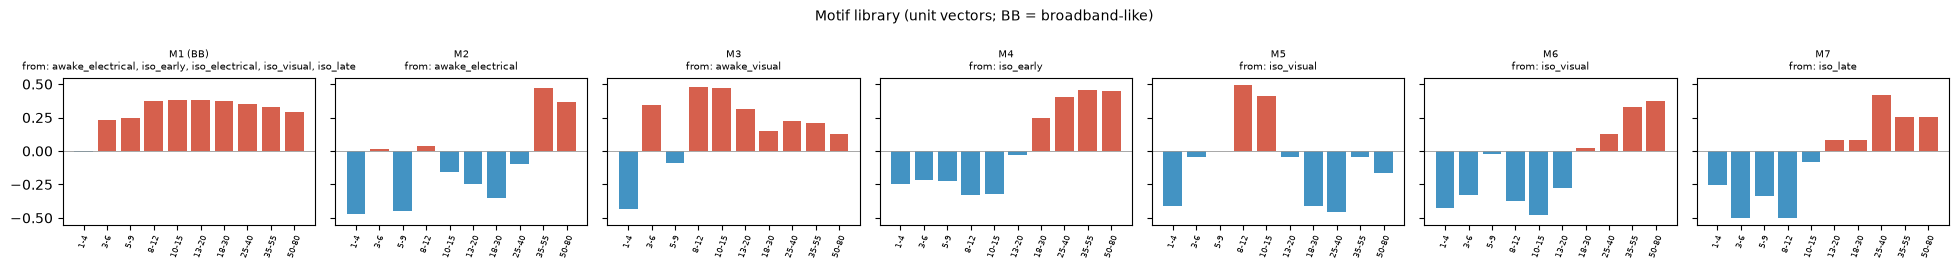

In [2]:
fig, axes = plt.subplots(1, K, figsize=(2.8 * K, 2.7), sharey=True, squeeze=False)
for i, (ax, m) in enumerate(zip(axes[0], motifs)):
    u = m.template
    ax.bar(range(10), u, color=np.where(u >= 0, "#d6604d", "#4393c3")); ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xticks(range(10), names, rotation=70, fontsize=6)
    ax.set_title(f"M{i + 1}{' (BB)' if m.broadband else ''}\nfrom: {', '.join(m.epochs)}", fontsize=7)
fig.suptitle("Motif library (unit vectors; BB = broadband-like)", fontsize=10)
fig.tight_layout(); save(fig, "1_library"); plt.show()

## 2. How many Gaussians per motif in each epoch

Cell text: k / number of peaks of the fitted density. Left: epoch-mean baseline. Right: 5-minute sliding baseline
removed first (section 7 explains why).

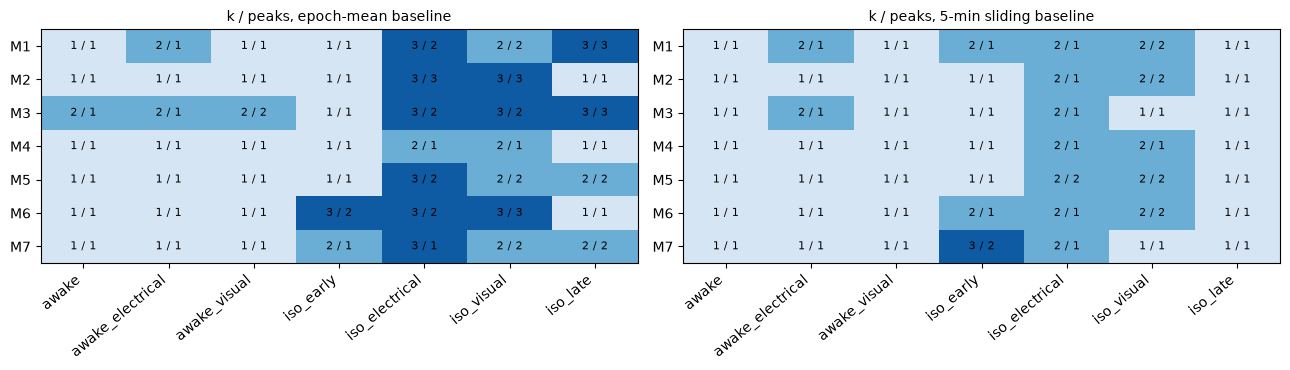

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (lab, MM) in zip(axes, (("epoch-mean baseline", M), ("5-min sliding baseline", M300))):
    kp = MM.kfit.pivot(index="motif", columns="epoch", values="k")[MM.epochs]
    pk = MM.kfit.pivot(index="motif", columns="epoch", values="peaks")[MM.epochs]
    ax.imshow(kp.values, cmap="Blues", vmin=0.5, vmax=3.5, aspect="auto")
    for i in range(kp.shape[0]):
        for j in range(kp.shape[1]):
            ax.text(j, i, f"{kp.values[i, j]} / {pk.values[i, j]}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(kp.shape[1]), kp.columns, rotation=40, ha="right"); ax.set_yticks(range(K), MN)
    ax.set_title(f"k / peaks, {lab}", fontsize=10)
fig.tight_layout(); save(fig, "2_k_per_epoch"); plt.show()

Each motif's expression in every epoch (own units), with the chosen Gaussians. Ticks mark the peaks of the fitted density.

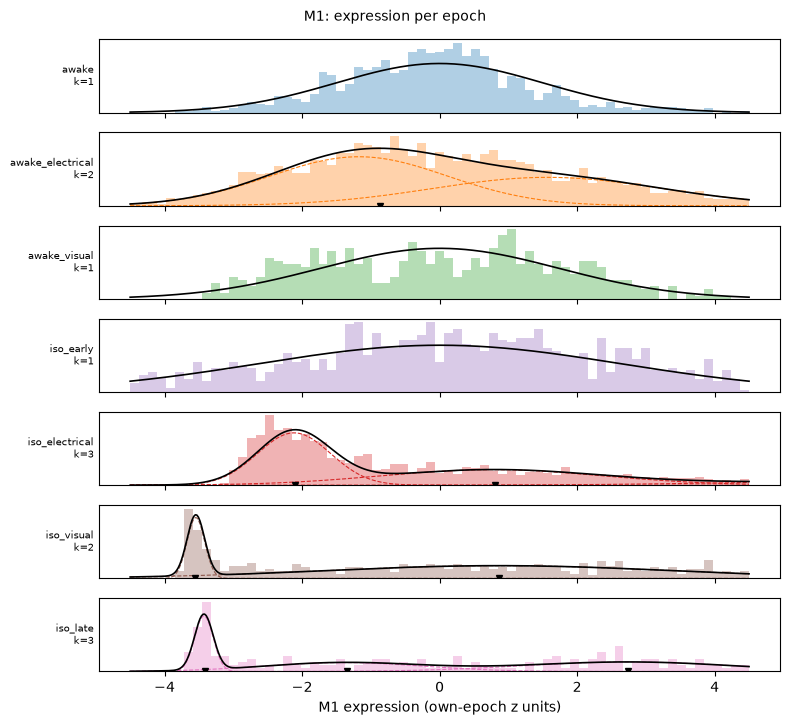

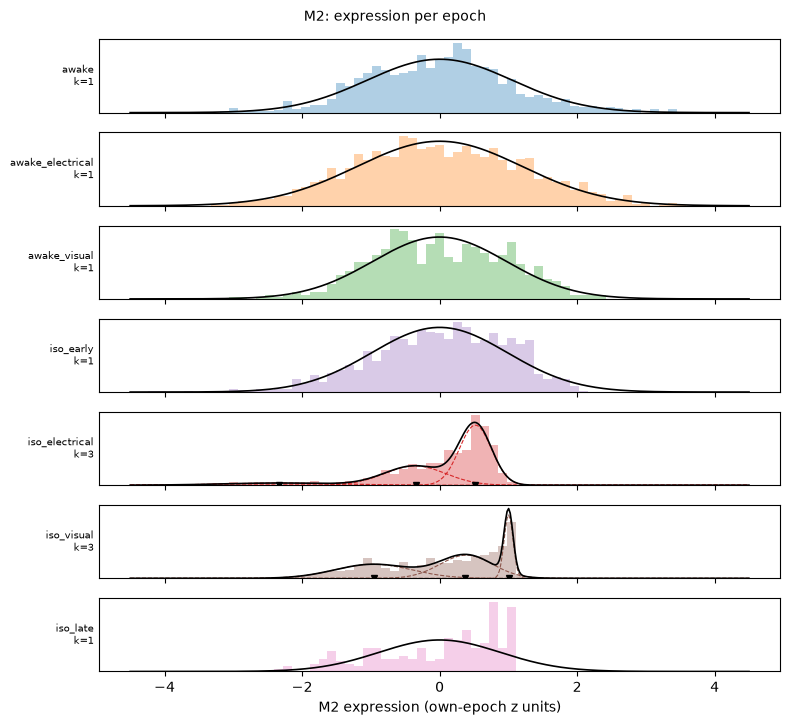

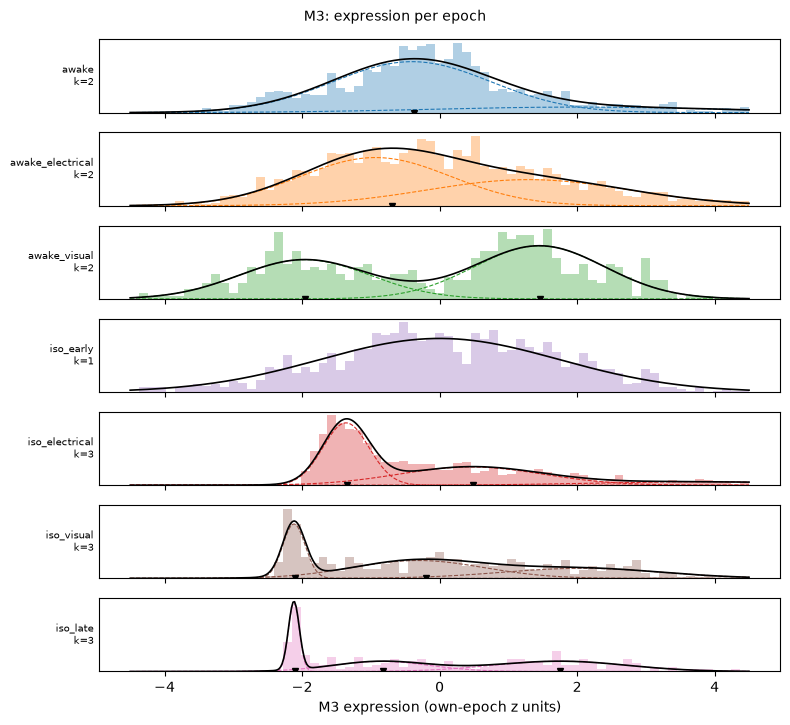

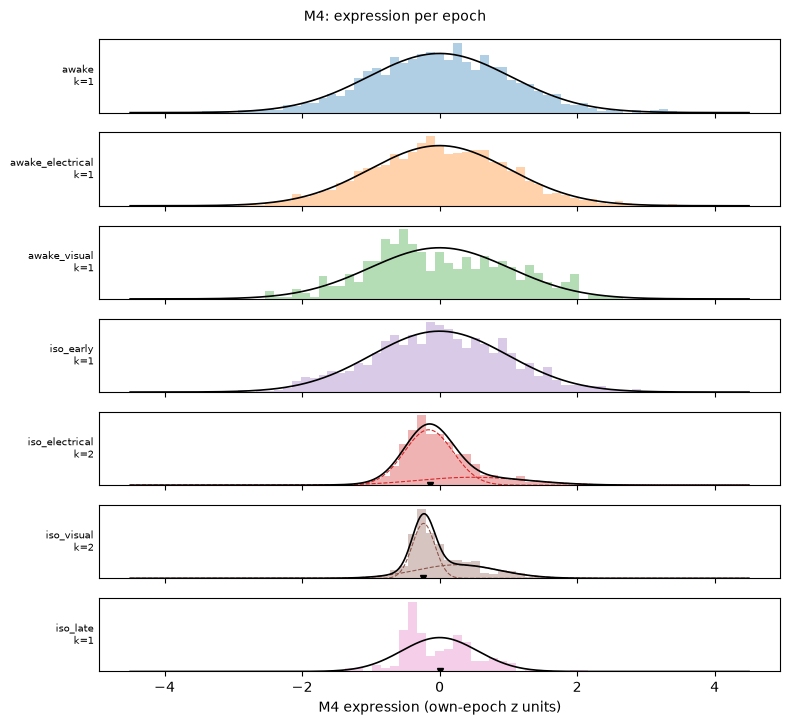

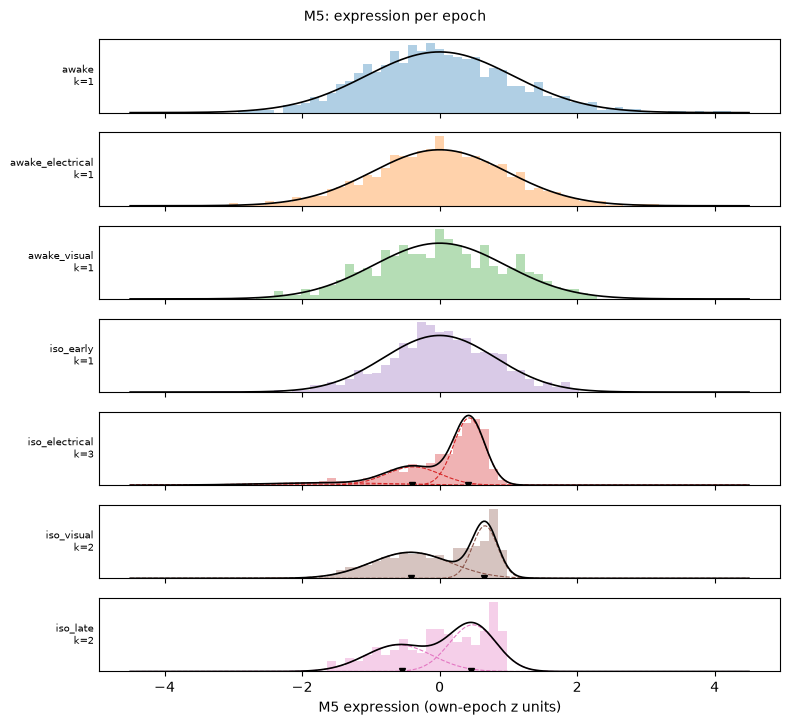

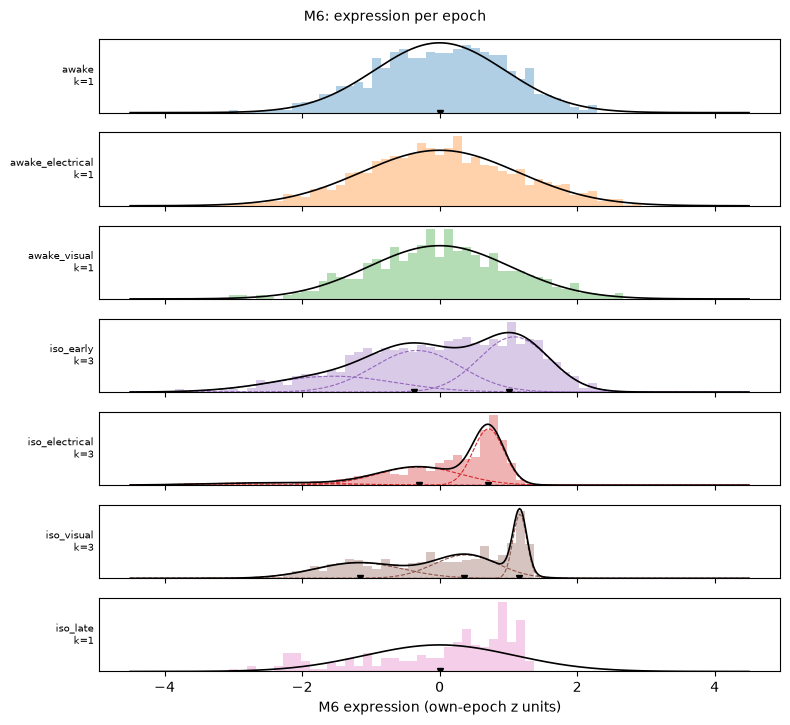

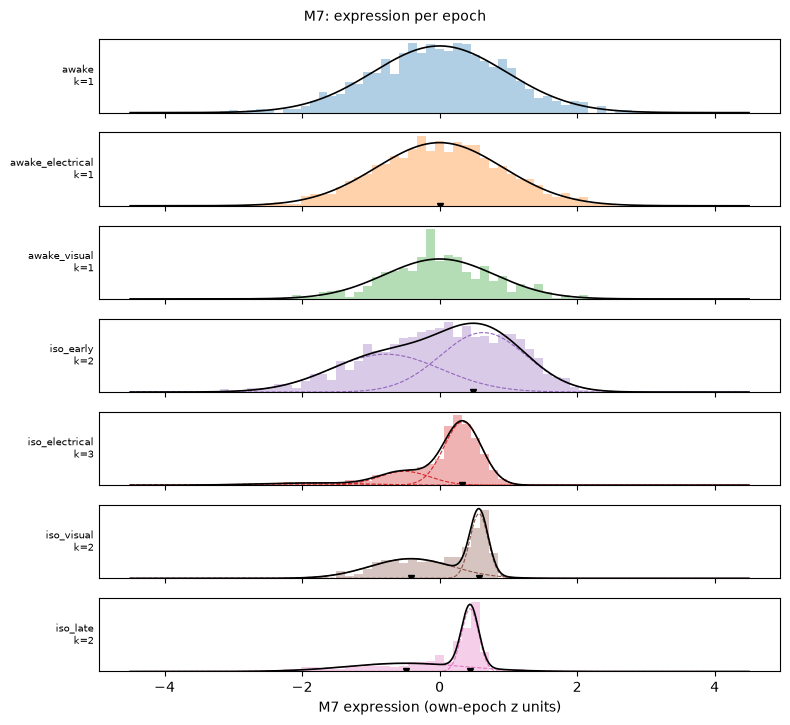

In [4]:
def npdf(x, m, s):
    return np.exp(-(x - m) ** 2 / (2 * s ** 2)) / (s * np.sqrt(2 * np.pi))

sec = M.second
for mi in range(K):
    fig, axes = plt.subplots(len(M.epochs), 1, figsize=(8, 1.05 * len(M.epochs)), sharex=True)
    xs = np.linspace(-4.5, 4.5, 400)
    for ax, e in zip(axes, M.epochs):
        x = sec.loc[sec.epoch == e, MN[mi]].dropna().to_numpy()
        ax.hist(x, bins=np.linspace(-4.5, 4.5, 70), density=True, color=ECOL[e], alpha=0.35)
        r = M.kfit[(M.kfit.motif == mi) & (M.kfit.epoch == e)].iloc[0]
        tot = np.zeros_like(xs)
        for mu_, sd_, w_ in zip(r["means"], r["sds"], r["weights"]):
            y = w_ * npdf(xs, mu_, sd_); tot += y
            if r["k"] > 1:
                ax.plot(xs, y, color=ECOL[e], lw=0.8, ls="--")
        ax.plot(xs, tot, color="k", lw=1.2)
        pk = xs[1:-1][(tot[1:-1] > tot[:-2]) & (tot[1:-1] > tot[2:])]
        ax.plot(pk, np.zeros_like(pk), "v", color="k", ms=5)
        ax.set_yticks([]); ax.set_ylabel(f"{e}\nk={r['k']}", rotation=0, ha="right", fontsize=7, va="center")
    axes[-1].set_xlabel(f"M{mi + 1} expression (own-epoch z units)")
    fig.suptitle(f"M{mi + 1}: expression per epoch", fontsize=10)
    fig.tight_layout(); save(fig, f"2_ridge_M{mi + 1}"); plt.show()

## 3. State: each epoch's baseline shift

Offset = where the epoch's baseline sits on each motif, relative to the pooled baseline (global z units). Bars: how
much of the shift lies along the best single motif, along the other motifs, and perpendicular to all of them.

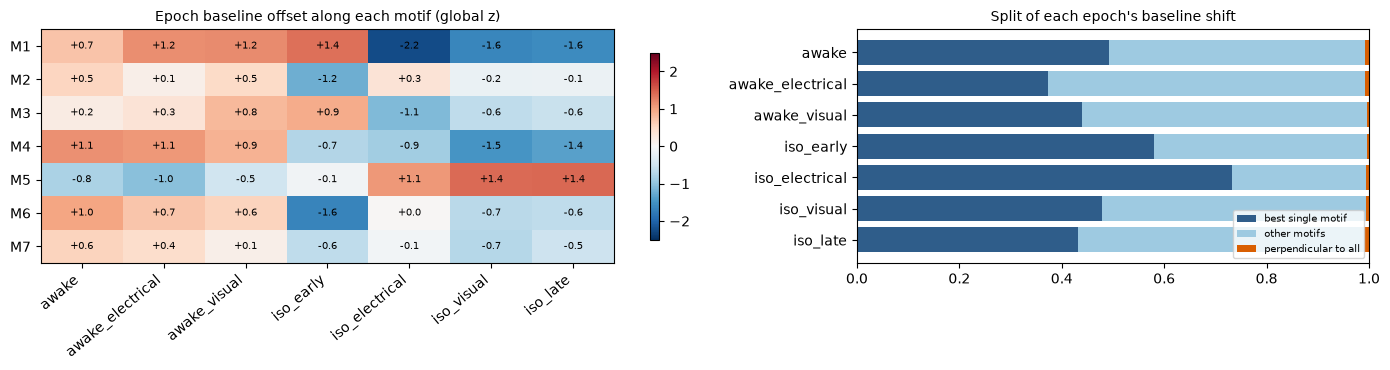

,shift size,share in motif span,share perpendicular
epoch,,,
awake,1.64,0.99,0.01
awake_electrical,1.90,0.99,0.01
awake_visual,1.79,1.00,0.00
iso_early,2.16,1.00,0.00
iso_electrical,2.60,0.99,0.01
iso_visual,2.35,0.99,0.01
iso_late,2.40,0.99,0.01


In [5]:
sh = M.shift
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
off = sh[[f"{m} offset" for m in MN]].T
off.index = MN
im = axes[0].imshow(off.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
for i in range(off.shape[0]):
    for j in range(off.shape[1]):
        axes[0].text(j, i, f"{off.values[i, j]:+.1f}", ha="center", va="center", fontsize=7)
axes[0].set_xticks(range(off.shape[1]), off.columns, rotation=40, ha="right"); axes[0].set_yticks(range(K), MN)
axes[0].set_title("Epoch baseline offset along each motif (global z)", fontsize=10)
fig.colorbar(im, ax=axes[0], shrink=0.8)
best = sh[[f"{m} share" for m in MN]].max(axis=1)
other = sh["share in motif span"] - best
axes[1].barh(sh.index, best, color="#2f5d8a", label="best single motif")
axes[1].barh(sh.index, other, left=best, color="#9ecae1", label="other motifs")
axes[1].barh(sh.index, sh["share perpendicular"], left=sh["share in motif span"], color="#d95f02", label="perpendicular to all")
axes[1].set_xlim(0, 1); axes[1].invert_yaxis(); axes[1].legend(fontsize=7, loc="lower right")
axes[1].set_title("Split of each epoch's baseline shift", fontsize=10)
fig.tight_layout(); save(fig, "3_baseline_shift"); plt.show()
sh[["shift size", "share in motif span", "share perpendicular"]].round(2)

## 4. The whole recording in one picture (view 1)

Every second on the first three principal components of the globally z-scored bands (every 3rd second plotted).
Diamonds: epoch baselines. Arrows: each motif's direction inside each epoch, converted to common units, drawn from that
epoch's baseline (toggle motifs in the legend). Black crosses: zero-labelled seconds; dark dots: suppression seconds.
Interactive version below; a static 2-D version follows.

In [6]:
Zc = data.Z - data.Z[data.epoch != ""].mean(0)
_, _, vt = np.linalg.svd(Zc[data.epoch != ""], full_matrices=False)
P = Zc @ vt[:3].T
gsd = data.env.std(axis=0, ddof=1)

def arrow_dir(mi, e):
    v = M.sd[e] / gsd * motifs[mi].template
    return v / np.linalg.norm(v)

sub = np.arange(0, data.t.size, 3)
fig = go.Figure()
for e in M.epochs:
    s = sub[data.epoch[sub] == e]
    fig.add_trace(go.Scatter3d(x=P[s, 0], y=P[s, 1], z=P[s, 2], mode="markers", name=e,
                               marker=dict(size=1.6, color=ECOL[e], opacity=0.45)))
cent = {e: Zc[data.epoch == e].mean(0) for e in M.epochs}
C3 = np.array([cent[e] @ vt[:3].T for e in M.epochs])
fig.add_trace(go.Scatter3d(x=C3[:, 0], y=C3[:, 1], z=C3[:, 2], mode="markers+text", text=M.epochs, name="epoch baselines",
                           marker=dict(size=6, symbol="diamond", color=[ECOL[e] for e in M.epochs], line=dict(color="black", width=1))))
mcol = ["#000000", "#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628"]
for mi in range(K):
    xs, ys, zs = [], [], []
    for e in M.epochs:
        a = cent[e] @ vt[:3].T
        b = (cent[e] + 2.0 * arrow_dir(mi, e)) @ vt[:3].T
        xs += [a[0], b[0], None]; ys += [a[1], b[1], None]; zs += [a[2], b[2], None]
    fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode="lines", name=f"M{mi + 1} arrows", line=dict(color=mcol[mi % 7], width=5),
                               visible=True if mi in (0, 2) else "legendonly"))
zs_ = sub[M.second["zero"].to_numpy()[sub]]
fig.add_trace(go.Scatter3d(x=P[zs_, 0], y=P[zs_, 1], z=P[zs_, 2], mode="markers", name="zero label",
                           marker=dict(size=2, color="black", symbol="x"), visible="legendonly"))
ss_ = sub[M.second["suppression"].to_numpy()[sub]]
fig.add_trace(go.Scatter3d(x=P[ss_, 0], y=P[ss_, 1], z=P[ss_, 2], mode="markers", name="suppression",
                           marker=dict(size=2, color="#222222"), visible="legendonly"))
fig.update_layout(height=650, margin=dict(l=0, r=0, t=30, b=0), title="Seconds, epoch baselines and motif directions (PC1–3)",
                  scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3"), legend=dict(itemsizing="constant"))
fig.write_html(OUT / "4_view1_3d.html", include_plotlyjs="cdn")
fig.show()

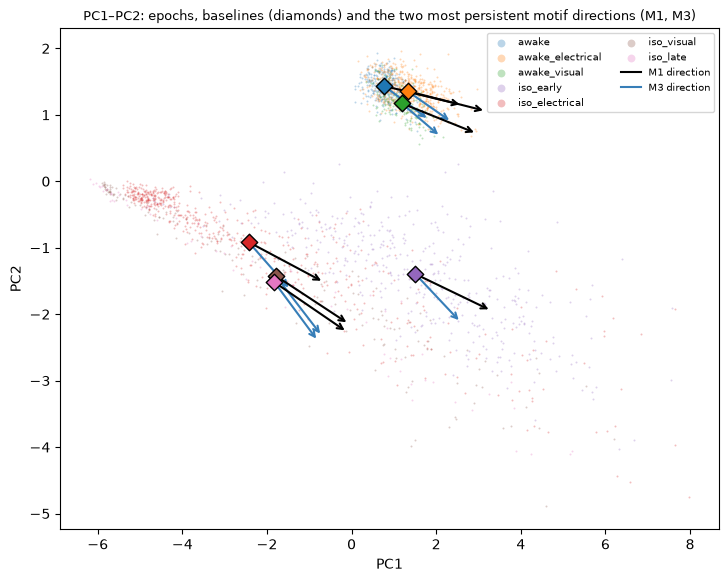

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for e in M.epochs:
    s = sub[data.epoch[sub] == e]
    ax.scatter(P[s, 0], P[s, 1], s=2, color=ECOL[e], alpha=0.3, lw=0, label=e)
for e in M.epochs:
    a = cent[e] @ vt[:2].T
    ax.scatter(*a, marker="D", s=70, color=ECOL[e], edgecolor="k", zorder=4)
    for mi, col in ((0, "k"), (2, "#377eb8")):
        b = 2.0 * arrow_dir(mi, e) @ vt[:2].T
        ax.annotate("", xy=a + b, xytext=a, arrowprops=dict(arrowstyle="->", color=col, lw=1.5))
ax.plot([], [], color="k", label="M1 direction"); ax.plot([], [], color="#377eb8", label="M3 direction")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, markerscale=4, ncol=2)
ax.set_title("PC1–PC2: epochs, baselines (diamonds) and the two most persistent motif directions (M1, M3)", fontsize=9)
save(fig, "4_view1_2d"); plt.show()

## 5. Inside each state (view 2): expression space

Seconds as their vector of motif expressions (own-epoch units, so every epoch is centred at zero), on the first two
principal components, separately for awake epochs and isoflurane epochs. One cloud per state means no discrete
sub-states inside it.

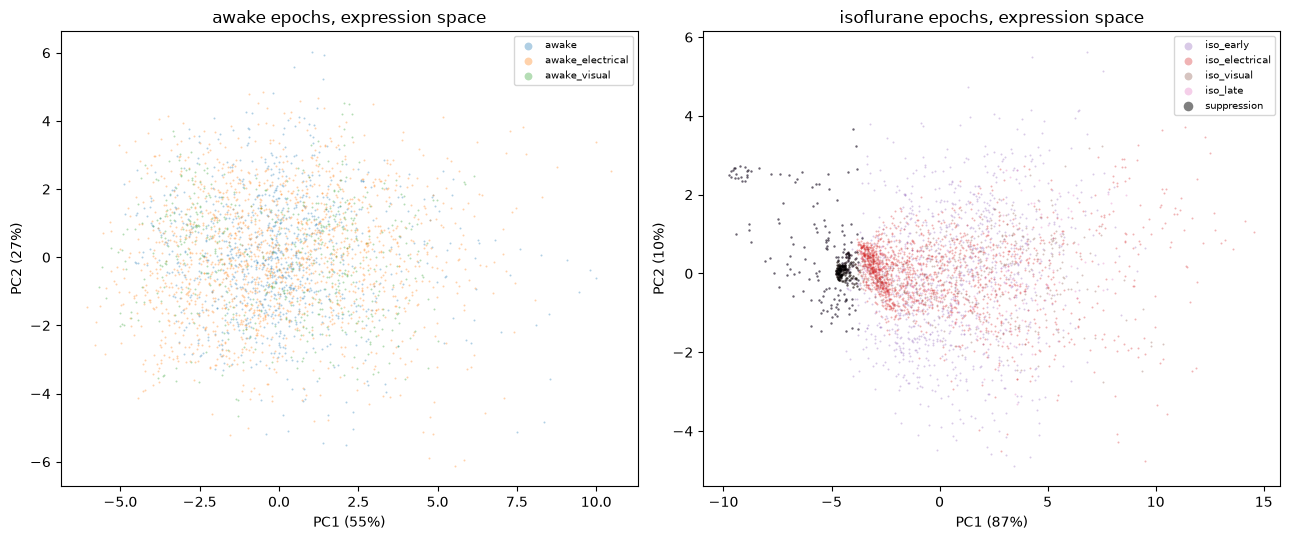

In [8]:
E = M.second[MN].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, group in zip(axes, (EP[:3], EP[3:])):
    sel = np.isin(data.epoch, group) & np.isfinite(E).all(1)
    X = E[sel] - E[sel].mean(0)
    _, sv, v2 = np.linalg.svd(X, full_matrices=False)
    Q = X @ v2[:2].T
    lab = data.epoch[sel]
    for e in group:
        k_ = lab == e
        ax.scatter(Q[k_, 0], Q[k_, 1], s=2, color=ECOL[e], alpha=0.35, lw=0, label=e)
    supp = M.second["suppression"].to_numpy()[sel]
    if supp.any():
        ax.scatter(Q[supp, 0], Q[supp, 1], s=3, color="k", alpha=0.5, lw=0, label="suppression")
    ve = sv ** 2 / (sv ** 2).sum()
    ax.set_xlabel(f"PC1 ({100 * ve[0]:.0f}%)"); ax.set_ylabel(f"PC2 ({100 * ve[1]:.0f}%)")
    ax.legend(fontsize=7, markerscale=4); ax.set_title(("awake" if group[0] == "awake" else "isoflurane") + " epochs, expression space")
fig.tight_layout(); save(fig, "5_view2_expression_space"); plt.show()

## 6. H1: do motif directions persist across states, and does their baseline move with the state?

**Persistence.** In sliding 5-minute windows, each band is z-scored within the window and the variance along each motif
direction is computed (u′Cu). A random direction gets 1 on average; the most any direction can get is the window's top
eigenvalue (grey line). A motif whose value stays well above 1 through awake and isoflurane keeps being a main axis
of fluctuation in both states.

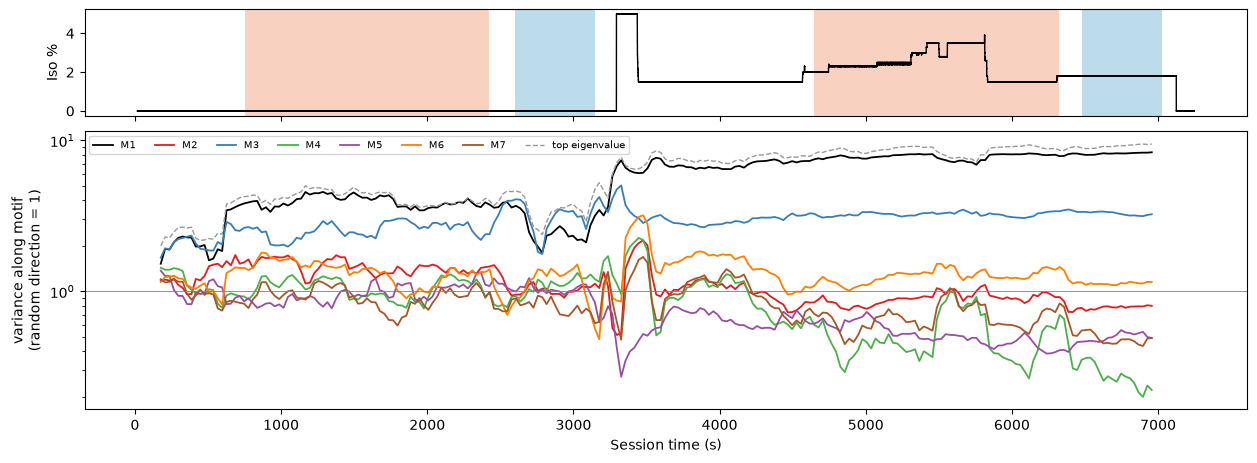

,"median, awake windows","median, isoflurane windows","share of windows > 1.5, awake","share of windows > 1.5, isoflurane"
M1,3.62,7.69,1.00,1.00
M2,1.35,0.90,0.24,0.03
M3,2.60,3.19,1.00,1.00
M4,1.06,0.54,0.02,0.03
M5,0.98,0.53,0.00,0.00
M6,1.29,1.28,0.15,0.21
M7,0.90,0.69,0.00,0.03


In [9]:
cw, enr, top = em.direction_over_time(data, motifs, window=300, step=30)
fig = plt.figure(figsize=(15, 5.2))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 2.6], hspace=0.08)
ax0 = fig.add_subplot(gs[0])
ax0.plot(info.iso_t, info.iso_level, "k", lw=1); ax0.set_ylabel("Iso %")
for _, a, b in info.stim_blocks: ax0.axvspan(a, b, color="#f4a582", alpha=0.5, lw=0)
for _, a, b in info.visual_blocks: ax0.axvspan(a, b, color="#92c5de", alpha=0.6, lw=0)
ax1 = fig.add_subplot(gs[1], sharex=ax0)
for mi in range(K):
    ax1.plot(cw, enr[:, mi], color=mcol[mi % 7], lw=1.3, label=f"M{mi + 1}")
ax1.plot(cw, top, color="0.6", lw=1, ls="--", label="top eigenvalue")
ax1.axhline(1, color="0.5", lw=0.6); ax1.set_yscale("log")
ax1.set_ylabel("variance along motif\n(random direction = 1)"); ax1.set_xlabel("Session time (s)")
ax1.legend(fontsize=7, ncol=8, loc="upper left"); plt.setp(ax0.get_xticklabels(), visible=False)
save(fig, "6_direction_persistence"); plt.show()
aw = cw < info.iso_on - 30; isw = cw > info.induction_end
persist = pd.DataFrame({"median, awake windows": np.median(enr[aw], 0), "median, isoflurane windows": np.median(enr[isw], 0),
                        "share of windows > 1.5, awake": (enr[aw] > 1.5).mean(0), "share of windows > 1.5, isoflurane": (enr[isw] > 1.5).mean(0)},
                       index=MN)
persist.round(2)

**Baseline trajectory.** For each motif, every second of the whole recording projected onto the motif (global z,
one fixed scale), with 60-s and 5-min rolling means (the moving baseline) and ±1 rolling SD (5 min). Shading:
electrical (orange) and visual (blue) blocks; dotted lines: isoflurane on and end of induction.

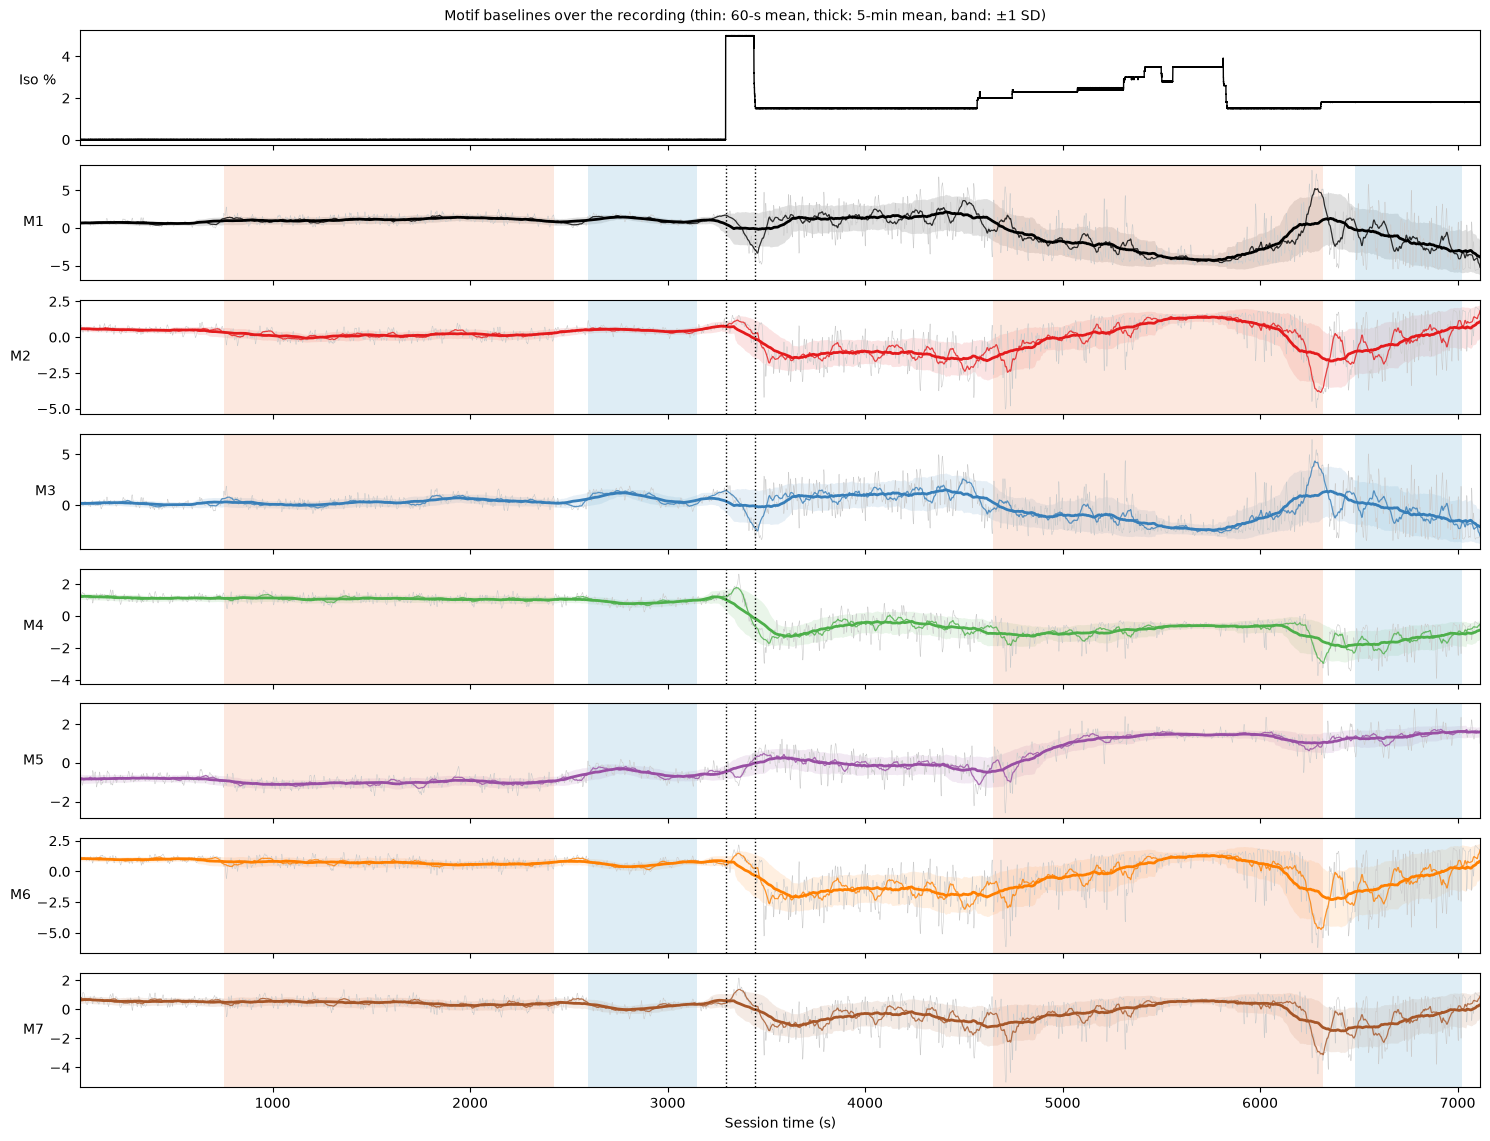

In [10]:
def baseline_panel(ax, mi, xlim=None):
    g = data.Z @ motifs[mi].template
    tt, m60, _ = em.rolling(g, data.t, 60)
    _, m300, s300 = em.rolling(g, data.t, 300)
    ax.plot(data.t, smooth(g, 5), color="0.8", lw=0.4)
    ax.fill_between(tt, m300 - s300, m300 + s300, color=mcol[mi % 7], alpha=0.12, lw=0)
    ax.plot(tt, m60, color=mcol[mi % 7], lw=0.9, alpha=0.8)
    ax.plot(tt, m300, color=mcol[mi % 7], lw=2)
    for _, a, b in info.stim_blocks: ax.axvspan(a, b, color="#f4a582", alpha=0.25, lw=0)
    for _, a, b in info.visual_blocks: ax.axvspan(a, b, color="#92c5de", alpha=0.3, lw=0)
    for x in (info.iso_on, info.induction_end): ax.axvline(x, color="k", ls=":", lw=1)
    ax.set_ylabel(f"M{mi + 1}", rotation=0, ha="right", va="center")
    if xlim: ax.set_xlim(*xlim)

fig, axes = plt.subplots(K + 1, 1, figsize=(15, 1.45 * (K + 1)), sharex=True)
axes[0].plot(info.iso_t, info.iso_level, "k", lw=1); axes[0].set_ylabel("Iso %", rotation=0, ha="right")
for mi in range(K):
    baseline_panel(axes[mi + 1], mi)
axes[-1].set_xlabel("Session time (s)"); axes[-1].set_xlim(data.t[0], data.t[-1])
fig.suptitle("Motif baselines over the recording (thin: 60-s mean, thick: 5-min mean, band: ±1 SD)", fontsize=10)
fig.tight_layout(); save(fig, "6_baseline_trajectories"); plt.show()

Zoom on induction, and around the start and end of each stimulus block (±5 min), for every motif (thick line: 60-s rolling mean).

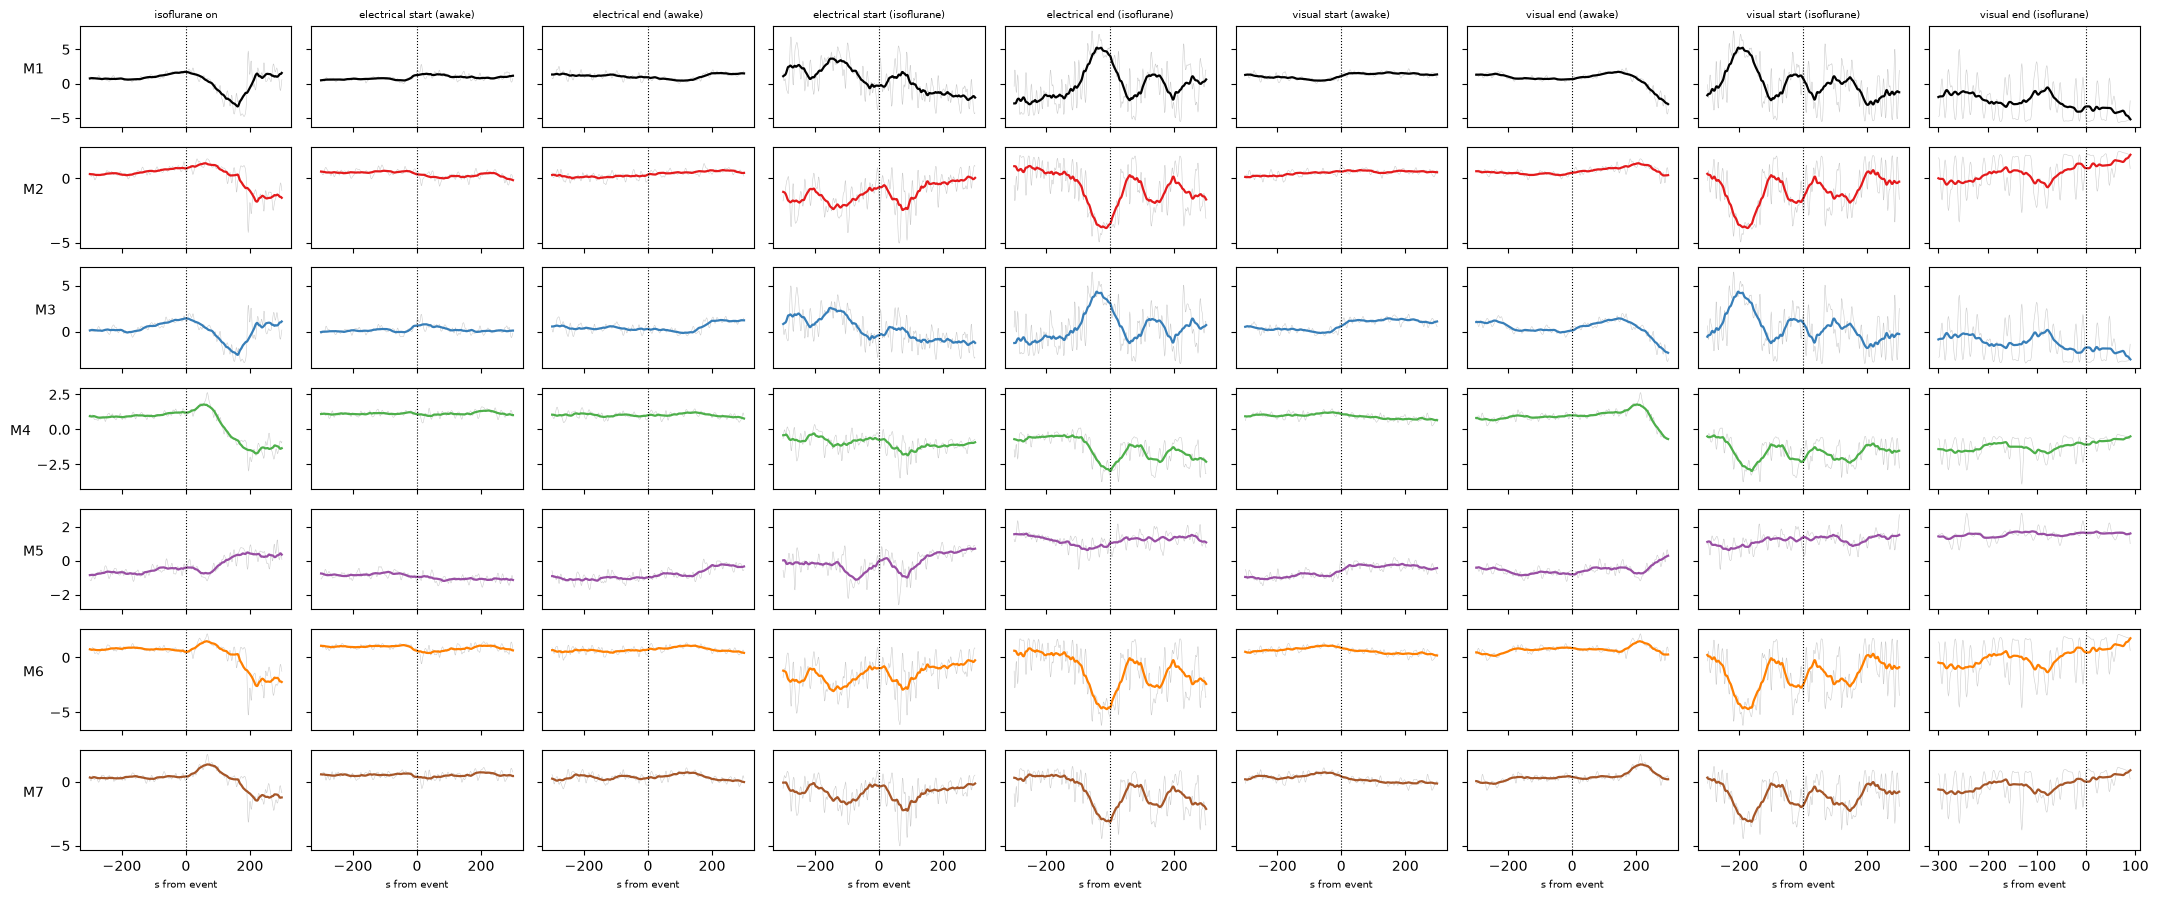

Baseline step: (mean 5 min after − mean 5 min before) / pooled SD, global z projection


,induction,electrical start (awake),electrical start (isoflurane),visual start (awake),visual start (isoflurane)
M1,-0.17,1.04,-1.08,1.79,-0.69
M2,-2.12,-1.20,0.58,0.92,0.56
M3,-0.04,0.41,-1.12,2.85,-0.70
M4,-5.02,0.02,-0.76,-1.14,0.02
M5,2.34,-1.26,0.73,2.56,0.49
M6,-2.52,-0.76,0.42,-1.23,0.47
M7,-2.02,-0.14,-0.08,-1.59,0.21


In [11]:
events = [("isoflurane on", info.iso_on)]
for lab, a, b in info.stim_blocks:
    events += [(f"electrical start ({lab})", a), (f"electrical end ({lab})", b)]
for lab, a, b in info.visual_blocks:
    events += [(f"visual start ({lab})", a), (f"visual end ({lab})", b)]
fig, axes = plt.subplots(K, len(events), figsize=(2.4 * len(events), 1.3 * K), sharex="col", sharey="row")
for mi in range(K):
    g = data.Z @ motifs[mi].template
    tt, m60, _ = em.rolling(g, data.t, 60)
    for j, (lab, x0) in enumerate(events):
        ax = axes[mi, j]
        w = (data.t > x0 - 300) & (data.t < x0 + 300)
        ax.plot(data.t[w] - x0, smooth(g, 5)[w], color="0.8", lw=0.4)
        w2 = (tt > x0 - 300) & (tt < x0 + 300)
        ax.plot(tt[w2] - x0, m60[w2], color=mcol[mi % 7], lw=1.6)
        ax.axvline(0, color="k", ls=":", lw=0.8)
        if mi == 0: ax.set_title(lab, fontsize=7)
        if j == 0: ax.set_ylabel(f"M{mi + 1}", rotation=0, ha="right")
for ax in axes[-1]: ax.set_xlabel("s from event", fontsize=7)
fig.tight_layout(); save(fig, "6_event_windows"); plt.show()

def step(mi, a0, a1, b0, b1):
    g = data.Z @ motifs[mi].template
    A, B = g[(data.t >= a0) & (data.t < a1)], g[(data.t >= b0) & (data.t < b1)]
    return (B.mean() - A.mean()) / np.sqrt((A.var() + B.var()) / 2)

steps = pd.DataFrame({"induction": [step(mi, info.iso_on - 330, info.iso_on - 30, info.induction_end, info.induction_end + 300) for mi in range(K)]}, index=MN)
for lab, a, b in info.stim_blocks + info.visual_blocks:
    kind = "electrical" if (lab, a, b) in info.stim_blocks else "visual"
    steps[f"{kind} start ({lab})"] = [step(mi, a - 300, a - 5, a + 5, a + 300) for mi in range(K)]
print("Baseline step: (mean 5 min after − mean 5 min before) / pooled SD, global z projection")
steps.round(2)

## 7. H2: does the baseline drift within an epoch?

For each motif, expression over time inside each epoch (own units; grey: 5-s smoothing; colour: 60-s mean; black:
5-min mean). Isoflurane level is overlaid (dashed, right axis) in isoflurane epochs, where it changes during the
electrical block. A trend in the black line means the poles are moving within the epoch.

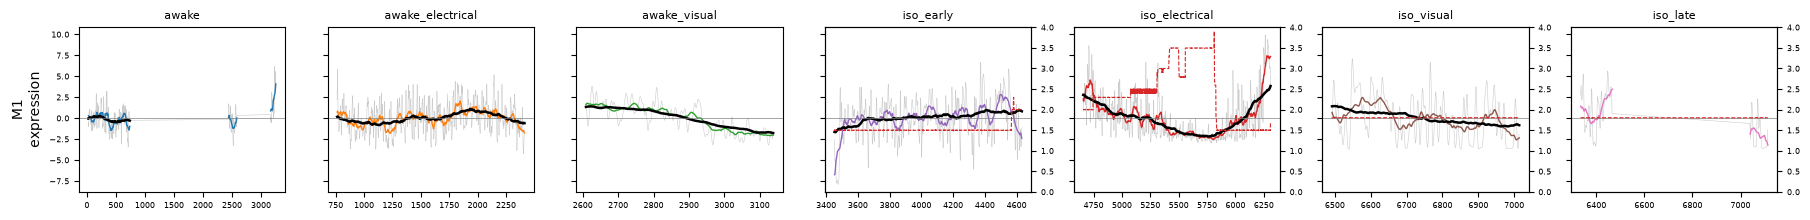

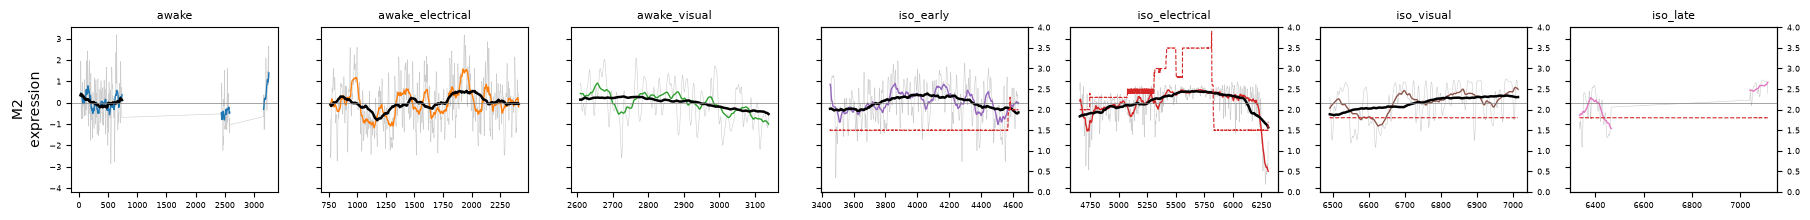

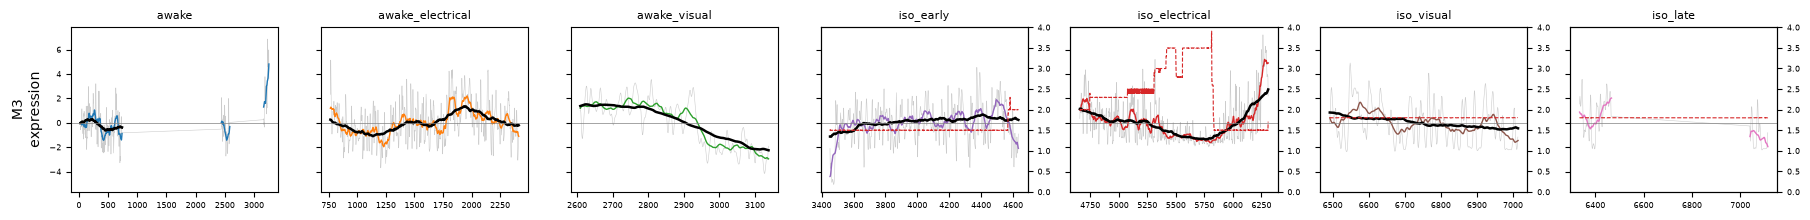

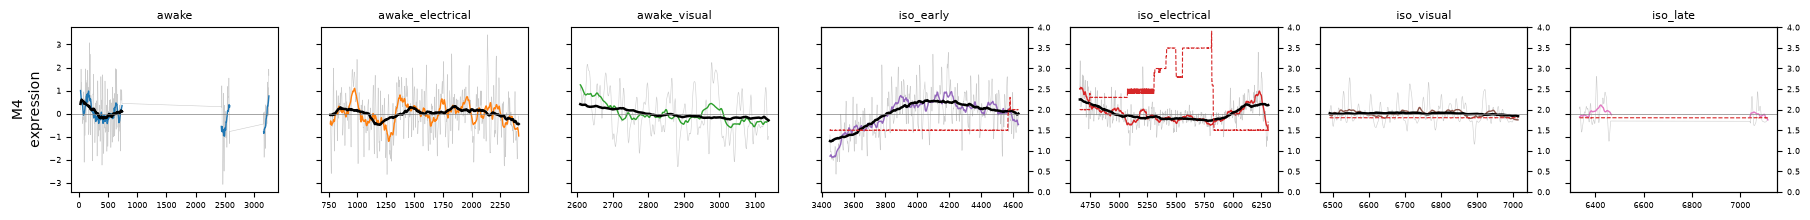

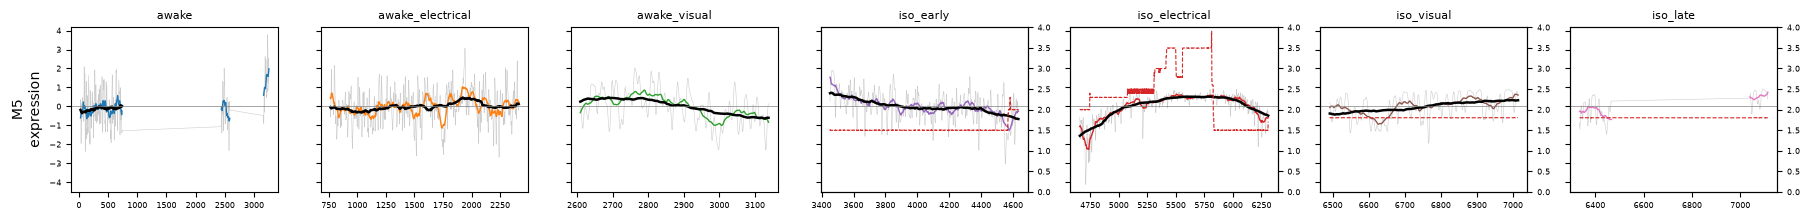

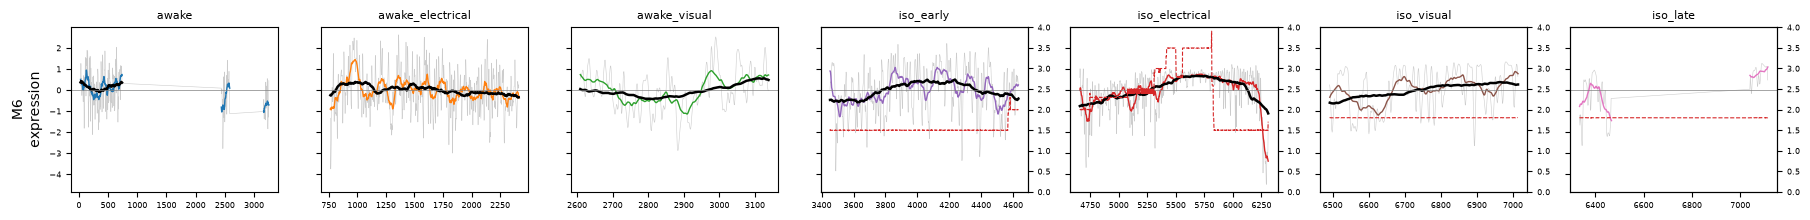

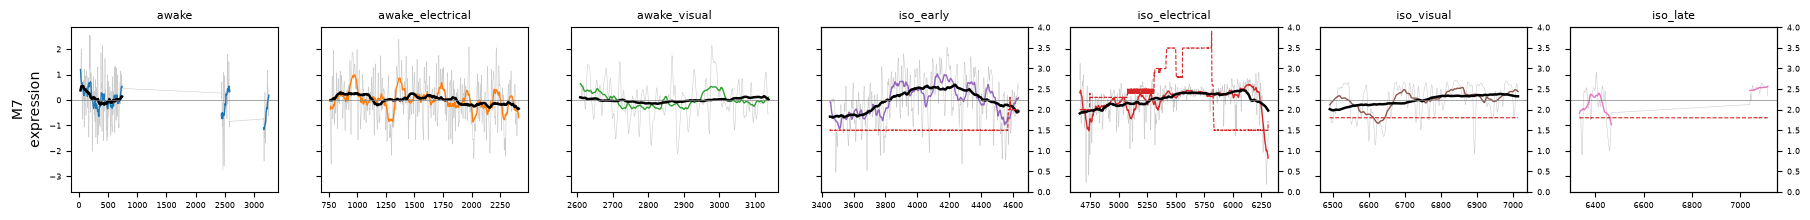

In [12]:
for mi in range(K):
    fig, axes = plt.subplots(1, len(M.epochs), figsize=(2.6 * len(M.epochs), 2.3), sharey=True)
    for ax, e in zip(axes, M.epochs):
        sel = (data.epoch == e) & np.isfinite(sec[MN[mi]].to_numpy())
        x, tt = sec.loc[sel, MN[mi]].to_numpy(), data.t[sel]
        _, m60, _ = em.rolling(x, tt, 60)
        g, m300, _ = em.rolling(x, tt, 300)
        ax.plot(tt, smooth(x, 5), color="0.8", lw=0.4)
        ax.plot(g, m60, color=ECOL[e], lw=1)
        ax.plot(g, m300, color="k", lw=1.8)
        ax.axhline(0, color="0.5", lw=0.5)
        if e.startswith("iso"):
            a2 = ax.twinx(); a2.plot(data.t[sel], iso_level[sel], color="#d62728", ls="--", lw=0.8)
            a2.set_ylim(0, 4); a2.tick_params(labelsize=6)
        ax.set_title(e, fontsize=8); ax.tick_params(labelsize=6)
    axes[0].set_ylabel(f"M{mi + 1}\nexpression")
    fig.tight_layout(); save(fig, f"7_within_epoch_M{mi + 1}"); plt.show()

Per motif and epoch: **slow share** = variance of the 5-min rolling mean ÷ total variance of the expression (how
much of the expression is slow drift), **trend** = linear slope in SD per 10 minutes, and the correlation of the
60-s rolling mean with isoflurane level (isoflurane epochs) or pupil size (awake epochs).

A phase-randomised surrogate can't serve as a reference here: it keeps the power spectrum, so it has the same amount
of slow drift by construction. Drift and slow fluctuation are the same thing spectrally; what can tell them apart is
whether the drift follows something else (dose, arousal, time since a stimulus).

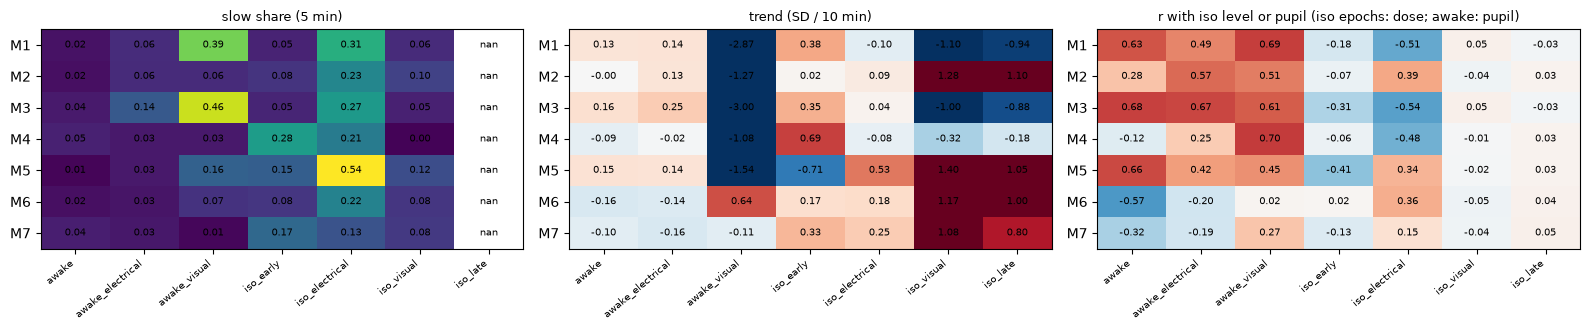

In [13]:
rows = []
for mi in range(K):
    for e in M.epochs:
        sel = (data.epoch == e) & np.isfinite(sec[MN[mi]].to_numpy())
        x, tt = sec.loc[sel, MN[mi]].to_numpy(), data.t[sel]
        g, m300, _ = em.rolling(x, tt, 300)
        _, m60, _ = em.rolling(x, tt, 60)
        ok = np.isfinite(m300)
        slope = np.polyfit(tt, x, 1)[0] * 600 / x.std()
        cov = np.interp(g, data.t, iso_level if e.startswith("iso") else pupil_s)
        ok60 = np.isfinite(m60)
        r = np.corrcoef(m60[ok60], cov[ok60])[0, 1] if cov[ok60].std() > 1e-6 else np.nan
        rows.append({"motif": MN[mi], "epoch": e, "slow share (5 min)": np.nanvar(m300[ok]) / x.var(),
                     "trend (SD / 10 min)": slope, "r with iso level or pupil": r})
drift = pd.DataFrame(rows)
drift.to_csv(OUT / "7_drift.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, col, cmap, lim in zip(axes, ["slow share (5 min)", "trend (SD / 10 min)", "r with iso level or pupil"],
                              ["viridis", "RdBu_r", "RdBu_r"], [(0, 0.5), (-1, 1), (-1, 1)]):
    pv = drift.pivot(index="motif", columns="epoch", values=col)[M.epochs]
    ax.imshow(pv.values, cmap=cmap, vmin=lim[0], vmax=lim[1], aspect="auto")
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            ax.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(pv.shape[1]), pv.columns, rotation=40, ha="right", fontsize=7); ax.set_yticks(range(K), pv.index)
    ax.set_title(col + (" (iso epochs: dose; awake: pupil)" if col.startswith("r") else ""), fontsize=9)
fig.tight_layout(); save(fig, "7_drift_summary"); plt.show()

**Did drift create the extra Gaussians?** k per motif and epoch with the epoch-mean baseline versus with a 5-minute
sliding baseline removed (same surrogate rule). If k drops after removing the sliding baseline, the extra Gaussians were
slow movement of one hump, not separate poles.

In [14]:
cmp = M.kfit[["motif", "epoch", "k", "peaks"]].merge(M300.kfit[["motif", "epoch", "k", "peaks"]], on=["motif", "epoch"],
                                                       suffixes=(" epoch-mean", " sliding 5 min"))
print(pd.crosstab(cmp["k epoch-mean"], cmp["k sliding 5 min"], margins=True))
cmp[cmp["k epoch-mean"] != cmp["k sliding 5 min"]].assign(motif=lambda d: "M" + (d.motif + 1).astype(str))

k sliding 5 min   1   2  3  All
k epoch-mean                   
1                24   1  0   25
2                 5   6  1   12
3                 3   9  0   12
All              32  16  1   49


,motif,epoch,k epoch-mean,peaks epoch-mean,k sliding 5 min,peaks sliding 5 min
2,M3,awake,2,1,1,1
16,M3,awake_visual,2,2,1,1
21,M1,iso_early,1,1,2,1
26,M6,iso_early,3,2,2,1
27,M7,iso_early,2,1,3,2
28,M1,iso_electrical,3,2,2,1
29,M2,iso_electrical,3,3,2,1
30,M3,iso_electrical,3,2,2,1
32,M5,iso_electrical,3,2,2,2
33,M6,iso_electrical,3,2,2,1


## 8. Over time (view 4)

The recording as a path through the view-1 space (10-s smoothing), coloured by time. Transitions show as the path
moving between regions.

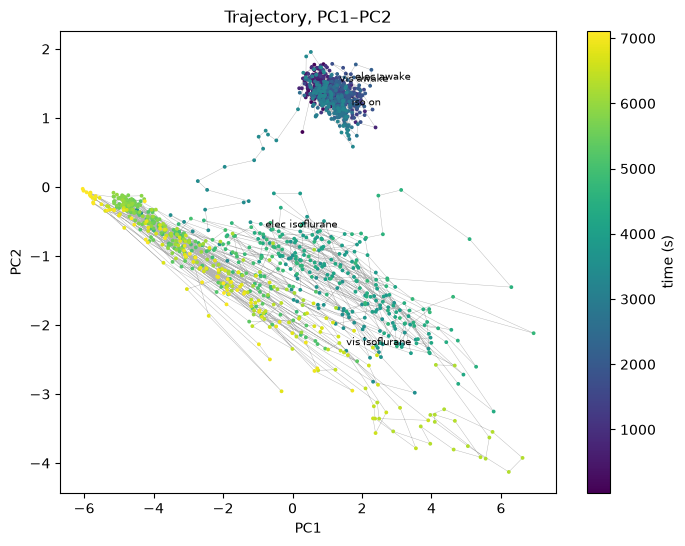

In [15]:
Ps = np.column_stack([smooth(P[:, i], 10) for i in range(3)])[::5]
ts = data.t[::5]
fig = go.Figure(go.Scatter3d(x=Ps[:, 0], y=Ps[:, 1], z=Ps[:, 2], mode="lines+markers",
                             line=dict(color=ts, colorscale="Viridis", width=3),
                             marker=dict(size=1.5, color=ts, colorscale="Viridis", colorbar=dict(title="time (s)")),
                             text=[f"{x:.0f} s, {e}" for x, e in zip(ts, data.epoch[::5])], hoverinfo="text"))
fig.update_layout(height=600, margin=dict(l=0, r=0, t=30, b=0), title="Trajectory through PC1–3 (10-s smoothing)",
                  scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3"))
fig.write_html(OUT / "8_trajectory_3d.html", include_plotlyjs="cdn")
fig.show()
fig, ax = plt.subplots(figsize=(8, 6))
scat = ax.scatter(Ps[:, 0], Ps[:, 1], c=ts, s=3, cmap="viridis")
ax.plot(Ps[:, 0], Ps[:, 1], color="0.7", lw=0.3, zorder=0)
for lab, x0 in [("iso on", info.iso_on)] + [(f"elec {l}", a) for l, a, _ in info.stim_blocks] + [(f"vis {l}", a) for l, a, _ in info.visual_blocks]:
    i = np.argmin(np.abs(ts - x0)); ax.annotate(lab, Ps[i, :2], fontsize=7, xytext=(4, 4), textcoords="offset points")
fig.colorbar(scat, label="time (s)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Trajectory, PC1–PC2")
save(fig, "8_trajectory_2d"); plt.show()

## Conclusions

**H1, across states.** Two of the 7 motifs persist as main directions of fluctuation in both states: M1 (broadband) and M3
stay well above a random direction in every 5-minute window (medians 3.6 → 7.7 and 2.6 → 3.2, awake → isoflurane).
The others sit near a random direction (≤ 1.35) and drop further under isoflurane.

- **The persistent motifs' baselines barely move at the awake → isoflurane transition** (step at induction −0.17 and
  −0.04 SD). They move *within* isoflurane instead: both fall steadily through the isoflurane-electrical block as the
  dose rises from 2% to 3.5%, bottom out around 5,800 s, and rebound sharply once the dose drops, peaking near 6,300 s.
  They also rise at the start of the awake visual block (+1.8 and +2.9 SD).
- **The motifs whose baselines do step at induction** (M4 −5.0, M6 −2.5, M5 +2.3, M2 −2.1, M7 −2.0 SD) are the
  non-persistent ones. So the state change happens along directions that are not the main axes of fluctuation inside
  either state.
- **So the hypothesis holds, with a twist.** Persistent directions do show a moving baseline, but it follows
  isoflurane depth and stimulation, not the awake/isoflurane switch itself.

**H2, within an epoch.** The baseline drifts in some epochs and not others:
- Spontaneous awake: stable (5-minute share of variance ≤ 0.05, no trend).
- Isoflurane + electrical: strong drift (slow share 0.13–0.54) that follows the dose (r = −0.51 for M1, −0.54 for M3,
  +0.34 to +0.39 for M2, M5, M6), with a lag after the dose falls.
- Awake visual: M1 and M3 drift down by about 3 SD per 10 minutes (slow share 0.39–0.46), together with pupil size
  (r 0.61–0.69).
- Isoflurane visual and late: trends of about ±1 SD per 10 minutes at a constant dose, possibly recovery after the
  electrical block.

**Drift explains most of the extra Gaussians.** With a 5-minute sliding baseline removed, motif × epoch cases with 2+
peaks drop from 17 to 6 of 49, and all awake cases become single-peaked. Five of the remaining 6 are in the isoflurane
visual block (stimulus-evoked).

**For the algorithm:** use a sliding baseline (about 5 minutes) rather than the epoch mean, and keep the baseline itself
as an output, since it carries dose and stimulation effects; for M1 and M3 under isoflurane it is the main signal.
Expression then becomes mostly single-peaked, and multi-peaked fits are reserved for stimulus-evoked periods.

Caveats: one channel, one session; M1 is broadband-like; the dose and the electrical block overlap in time, so dose and
stimulation effects can't be fully separated here.